# 09 - Principal components of the EEX TTF curve vs the price models

The EEX Market Data Hub serves the last 33 sessions of every TTF futures contract (6 October to 19 November 2026,
collected with the local scraper, see `data/README.md`). That is 32 daily moves of the **whole curve**, Dec-26 to
Dec-28, from a source independent of the Yahoo/NYMEX contracts used to fit $\kappa_{\mathbb Q}$ in notebook 06.

Three questions:

1. **How many factors move the curve?** PCA of the daily log-returns, with bootstrap intervals (32 days is short).
2. **Which price dynamics are consistent with these moves?** Volatility of each contract against the three models
   used in the valuation: one-factor with the historical $\kappa_{\mathbb P} = 4.78$, one-factor with
   $\kappa_{\mathbb Q}$ from futures vols, and the Schwartz-Smith two-factor fit.
3. **How much does the storage spread move?** Volatility of the winter 2027/28 minus summer 2027 log-spread, the
   quantity that drives the extrinsic value of the contract.

Formulas and conventions: docstring of `gasstorage.models.curve_pca`. Instantaneous model covariance per year:

$$\Sigma_{ij} = \sigma_\chi^2 e^{-\kappa(\tau_i+\tau_j)} + \sigma_\xi^2
+ \rho\sigma_\chi\sigma_\xi\left(e^{-\kappa\tau_i}+e^{-\kappa\tau_j}\right),$$

rank one ($\sigma_\xi = 0$) for the one-factor models, so one component explains 100 % of their variance.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir("..")

from gasstorage import plotting
from gasstorage.config import load_config
from gasstorage.data import eex_hub
from gasstorage.data.ttf import get_contract_history, get_ttf_history
from gasstorage.models.curve_pca import (
    curve_pca,
    curve_returns,
    delivery_tau,
    explained_shares,
    locked_groups,
    model_covariance,
    spread_vol,
    spread_weights,
)
from gasstorage.models.vol_term_structure import (
    fit_one_factor_kappa,
    fit_two_factor,
    vol_ratio_table,
)

plotting.apply_style()
cfg = load_config("configs/storage_default.yaml")
panel = eex_hub.futures_panel(eex_hub.DEFAULT_ROOT)
ret = curve_returns(panel, "2026-12", "2028-12")  # contracts alive over the whole window
print(
    f"{len(ret)} daily moves, {ret.index.min().date()} to {ret.index.max().date()}, "
    f"{ret.shape[1]} months"
)

32 daily moves, 2026-10-07 to 2026-11-19, 25 months


**Months that move in lockstep.** Illiquid months are settled from their quarter: their daily returns are
identical to within 0.1 %. The PCA is also run on one series per locked group as a check.

In [2]:
groups = locked_groups(ret)
print("locked groups:", [f"{g[0]}..{g[-1]}" for g in groups if len(g) > 1])
res = curve_pca(ret)
res_distinct = curve_pca(ret[[g[0] for g in groups]])
shares = pd.DataFrame(
    {
        "share (all months)": res.shares[:3],
        "95 % CI lo": res.share_ci["lo"].to_numpy(),
        "95 % CI hi": res.share_ci["hi"].to_numpy(),
        "share (one month per locked group)": res_distinct.shares[:3],
    },
    index=["PC1", "PC2", "PC3"],
)
(100 * shares).round(1)

locked groups: ['2027-10..2027-12', '2028-02..2028-03', '2028-04..2028-06', '2028-10..2028-12']


,share (all months),95 % CI lo,95 % CI hi,share (one month per locked group)
PC1,90.5,83.6,94.5,91.7
PC2,5.1,2.7,9.8,5.1
PC3,2.3,1.1,5.1,1.5


**Models.** Same parameters as the valuation (notebooks 02 and 06).

In [3]:
contracts = get_contract_history([])
starts = {c: pd.Period(c, "M").start_time for c in contracts.columns}
table = vol_ratio_table(contracts, starts, get_ttf_history())
k_q = fit_one_factor_kappa(table)
two = fit_two_factor(table, front_vol=cfg.model.sigma)
models = {
    f"1F historical, kappa = {cfg.model.kappa:.2f}": (cfg.model.kappa, cfg.model.sigma, 0.0, 0.0),
    f"1F risk-neutral, kappa = {k_q.kappa:.2f}": (k_q.kappa, cfg.model.sigma, 0.0, 0.0),
    "2F Schwartz-Smith": (two.kappa, two.sigma_chi, two.sigma_xi, two.rho),
}
tau = delivery_tau(ret.columns, ret.index)
cov = {name: model_covariance(tau, *p) for name, p in models.items()}

vol = ret.std(ddof=1).to_numpy() * np.sqrt(252)
se = vol / np.sqrt(2 * (len(ret) - 1))
vols = pd.DataFrame({"tau (y)": tau, "EEX": vol, "SE": se}, index=ret.columns.astype(str))
for name, c in cov.items():
    vols[name] = np.sqrt(np.diag(c))
z = {name: (vols[name] - vols["EEX"]) / vols["SE"] for name in models}
print("model - data, in standard errors (min / max over the 25 contracts):")
for name, s in z.items():
    print(f"  {name:<32s} {s.min():6.1f} / {s.max():5.1f}")
vols.round(3)

model - data, in standard errors (min / max over the 25 contracts):
  1F historical, kappa = 4.78        -7.9 /  -2.2
  1F risk-neutral, kappa = 0.33      -1.5 /   0.7
  2F Schwartz-Smith                  -1.9 /   0.7


,tau (y),EEX,SE,"1F historical, kappa = 4.78","1F risk-neutral, kappa = 0.33",2F Schwartz-Smith
delivery_month,,,,,,
2026-12,0.093,0.620,0.079,0.444,0.673,0.678
2027-01,0.178,0.622,0.079,0.296,0.655,0.653
2027-02,0.263,0.619,0.079,0.197,0.637,0.629
2027-03,0.340,0.620,0.079,0.137,0.621,0.608
2027-04,0.425,0.556,0.071,0.091,0.604,0.586
2027-05,0.507,0.562,0.071,0.061,0.588,0.566
2027-06,0.592,0.560,0.071,0.041,0.572,0.546
2027-07,0.674,0.520,0.066,0.028,0.557,0.528
2027-08,0.759,0.518,0.066,0.018,0.542,0.510


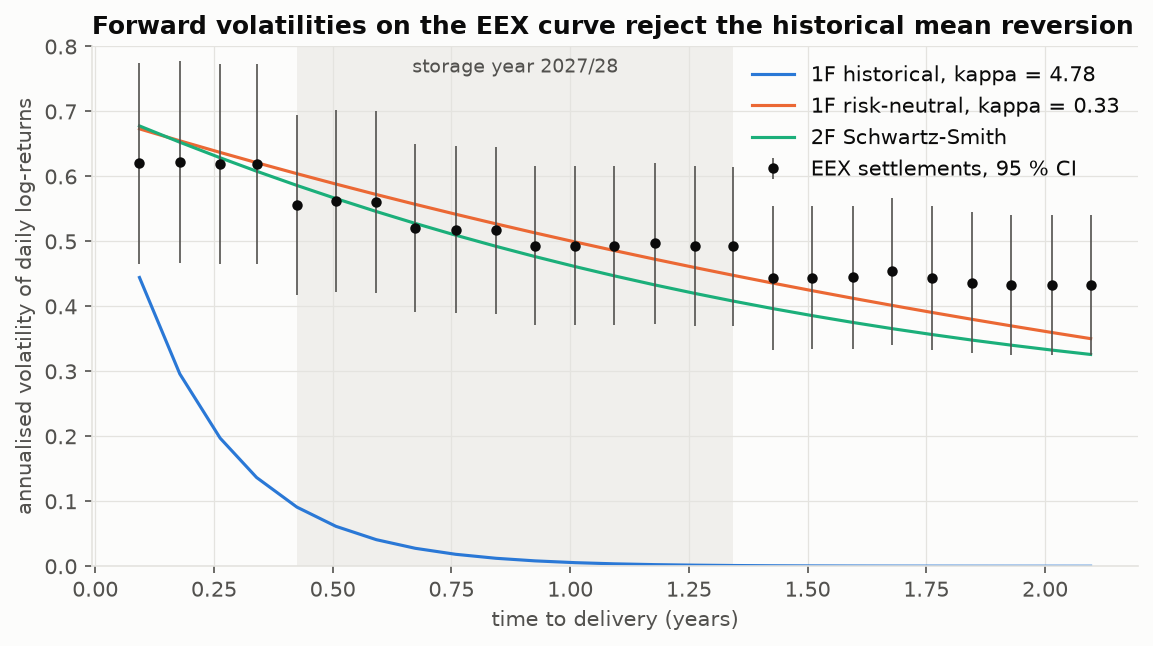

In [4]:
fig, ax = plt.subplots()
ax.errorbar(
    vols["tau (y)"],
    vols["EEX"],
    yerr=1.96 * vols["SE"],
    fmt="o",
    ms=4,
    color=plotting.TEXT_PRIMARY,
    ecolor=plotting.TEXT_SECONDARY,
    elinewidth=0.8,
    capsize=0,
    label="EEX settlements, 95 % CI",
    zorder=3,
)
for name, color in zip(models, plotting.SERIES[:3], strict=True):
    ax.plot(vols["tau (y)"], vols[name], color=color, label=name)
storage = (ret.columns >= pd.Period("2027-04", "M")) & (ret.columns <= pd.Period("2028-03", "M"))
ax.axvspan(tau[storage].min(), tau[storage].max(), color=plotting.NEUTRAL_FILL, lw=0, zorder=0)
ax.text(
    tau[storage].mean(),
    0.76,
    "storage year 2027/28",
    ha="center",
    color=plotting.TEXT_SECONDARY,
    fontsize=9,
)
ax.set(
    xlabel="time to delivery (years)",
    ylabel="annualised volatility of daily log-returns",
    title="Forward volatilities on the EEX curve reject the historical mean reversion",
    ylim=(0, 0.8),
)
ax.legend(loc="upper right")
display(Image(plotting.save_figure(fig, "09_vol_term_structure_eex")))

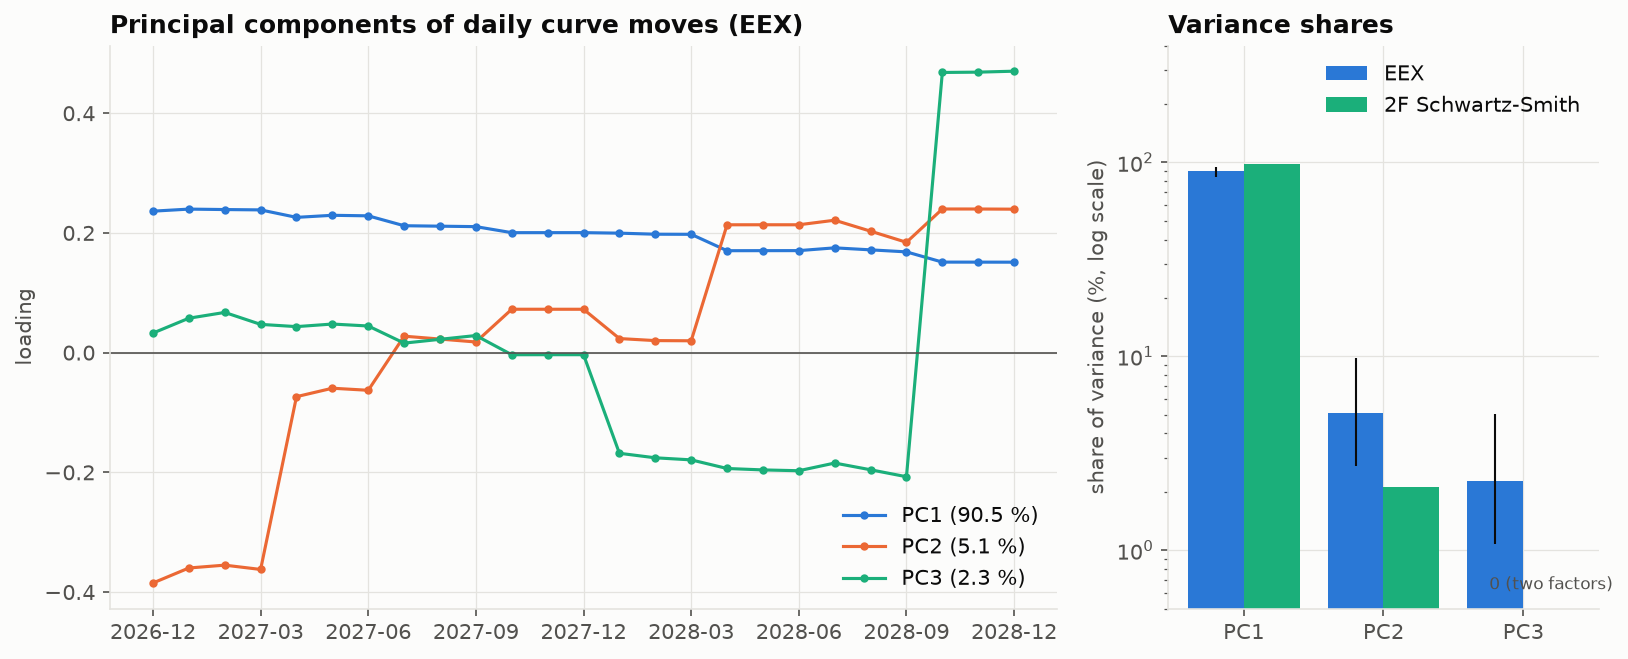

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.5), width_ratios=[2.2, 1])
x = np.arange(len(ret.columns))
for k, color in zip(["PC1", "PC2", "PC3"], plotting.SERIES[:3], strict=True):
    a1.plot(
        x,
        res.loadings[k],
        marker="o",
        ms=3,
        color=color,
        label=f"{k} ({100 * res.shares[int(k[2]) - 1]:.1f} %)",
    )
a1.axhline(0, color=plotting.TEXT_SECONDARY, lw=0.8)
a1.set_xticks(x[::3], [str(m) for m in ret.columns[::3]])
a1.set(ylabel="loading", title="Principal components of daily curve moves (EEX)")
a1.legend(loc="lower right")
two_name = "2F Schwartz-Smith"
model_share = explained_shares(cov[two_name])[:3]
pos = np.arange(3)
a2.bar(pos - 0.2, 100 * res.shares[:3], 0.4, color=plotting.SERIES[0], label="EEX")
a2.errorbar(
    pos - 0.2,
    100 * res.shares[:3],
    yerr=[100 * (res.shares[:3] - res.share_ci["lo"]), 100 * (res.share_ci["hi"] - res.shares[:3])],
    fmt="none",
    ecolor=plotting.TEXT_PRIMARY,
    elinewidth=1,
)
a2.bar(pos + 0.2, 100 * model_share, 0.4, color=plotting.SERIES[2], label=two_name)
a2.set_yscale("log")
a2.set_xticks(pos, ["PC1", "PC2", "PC3"])
a2.set(ylabel="share of variance (%, log scale)", title="Variance shares", ylim=(0.5, 400))
a2.text(
    2.2, 0.6, "0 (two factors)", ha="center", va="bottom", fontsize=8, color=plotting.TEXT_SECONDARY
)
a2.legend(loc="upper right")
fig.tight_layout()
display(Image(plotting.save_figure(fig, "09_curve_pca_eex")))

**Storage spread.** Day-weighted log-spread winter 2027/28 (Oct-27 to Mar-28) minus summer 2027 (Apr-27 to
Sep-27).

In [6]:
w = spread_weights(ret.columns, long=("2027-10", "2028-03"), short=("2027-04", "2027-09"))
v, v_se = spread_vol(ret, w)
rows = {"EEX (sample)": (v, v_se)}
rows |= {name: (float(np.sqrt(w @ c @ w)), np.nan) for name, c in cov.items()}
spread = pd.DataFrame(rows, index=["vol of winter - summer log-spread", "SE"]).T
spread["(model - EEX) / SE"] = (spread.iloc[:, 0] - v) / v_se
spread.round(3)

,vol of winter - summer log-spread,SE,(model - EEX) / SE
EEX (sample),0.099,0.013,0.000
"1F historical, kappa = 4.78",0.038,NaN,-4.853
"1F risk-neutral, kappa = 0.33",0.085,NaN,-1.103
2F Schwartz-Smith,0.114,NaN,1.207


## Findings

* **One factor dominates, but not completely.** PC1 (a level move, larger at the front) explains 90.5 % of the
  variance of daily curve moves (95 % bootstrap interval 83.6-94.5 %). PC2 (5.1 %) is a slope: front winter
  2026/27 against 2028. PC3 (2.3 %) mostly isolates the Q4-28 block, one of the months settled from their quarter.
  Keeping one month per locked group gives the same shares (91.7 / 5.1 / 1.5 %).
* **The historical mean reversion is rejected by the curve.** With $\kappa_{\mathbb P} = 4.78$ the 2027/28 forwards
  would have a volatility of 0.1 to 9 %; on EEX they move at 49-56 %, 6 to 8 standard errors away for every
  contract of the storage year. This is an independent confirmation, on another source and the whole curve, of the
  notebook 06 result behind the headline: valuing the storage with the historical front-month dynamics ignores how
  the forwards actually move.
* **The risk-neutral one-factor model fits the EEX volatilities out of sample.** $\kappa_{\mathbb Q} = 0.33$, fitted on
  three Yahoo/NYMEX contracts, matches all 25 EEX contracts within 1.5 standard errors. The two-factor fit
  is slightly too low on the long end, also within about 2 SE.
* **The two-factor model is too correlated.** It gives PC1 = 97.9 % of the variance, above the 95 % interval of the
  data: the curve decorrelates more than the fitted $\rho$ and $\sigma_\xi$ imply (sample PCA tends to overstate PC1,
  so the gap is if anything larger). With 32 days this is indicative only.
* **The storage spread moves at about 10 % a year,** against 50 % for the level. Both risk-neutral models get it
  right within about 1.2 SE (8.5 % one-factor, 11.4 % two-factor). This low spread volatility is why the extrinsic
  value under $\mathbb Q$ is small: on a backwardated curve the option to store pays only if winter overtakes summer,
  and the log-spread on 19 November (about -13 %) is larger than one year of its volatility.

**Limits.** 32 daily moves in one regime (October-November 2026): wide intervals, and volatilities change over time.
The window rolls; the analysis can be re-run after each collection to accumulate a longer sample.